In [21]:
from getpass import getuser # Libaray to copy things
from pathlib import Path # Object oriented libary to deal with paths
from dask.utils import format_bytes
from distributed import Client, progress, wait # Libaray to orchestrate distributed resources
#from dask_jobqueue import SLURMCluster # Setting up distributed memories via slurm
import numpy as np # Pythons standard array library
import xarray as xr # Libary to work with labeled n-dimensional data
import dask # Distributed data libary
import dask.distributed
import multiprocessing
from dask.diagnostics import ProgressBar
import glob, os
from matplotlib.lines import Line2D

from matplotlib.patches import Patch
from scipy.ndimage import gaussian_filter1d
from subprocess import run, PIPE
import sys
import os
from sklearn.neighbors import KernelDensity
import gc
from concurrent.futures import ProcessPoolExecutor
import seaborn as sns
import warnings
warnings.filterwarnings(action='ignore')
dask.config.config.get('distributed').get('dashboard').update({'link':'{JUPYTERHUB_SERVICE_PREFIX}/proxy/{port}/status'})
import pandas as pd
from scipy.interpolate import CloughTocher2DInterpolator, LinearNDInterpolator, NearestNDInterpolator

In [22]:
from matplotlib.ticker import (MultipleLocator, FormatStrFormatter, AutoMinorLocator)
from matplotlib import pyplot as plt # Standard Plotting library
from matplotlib import cm
from matplotlib.colors import ListedColormap, LinearSegmentedColormap
from matplotlib.ticker import (MultipleLocator, FormatStrFormatter, AutoMinorLocator)
from cartopy import crs as ccrs # Cartography library
from cartopy.mpl.ticker import LongitudeFormatter, LatitudeFormatter
import cartopy.feature as cfeature
import matplotlib.ticker as mticker
import matplotlib.tri as tri

In [23]:
#'''Provides information about the CPU and starts the dask client'''
ncpu = multiprocessing.cpu_count()
processes = False
nworker = 1
threads = ncpu // nworker
print(f"Number of CPUs: {ncpu}, number of threads: {threads}, number of workers: {nworker}, processes: {processes}")
client = Client(processes=processes,
 threads_per_worker=threads,
 n_workers=nworker,
 memory_limit='1000GB'
 )

Number of CPUs: 64, number of threads: 64, number of workers: 1, processes: False


In [24]:
latitude = [30,60]
mask = '01'

# CMIP6 multi-model distribution, replaces CESM2 when mask == '1' (daily precipitation > 1 mm)
CMIP6_DIR        = '/home/jwille/xenon_data/NextGEMS/mid_lat_precip/CMIP6'   # output of cmip6_precip_cover_calc.py
CMIP6_THRESHOLD  = 1.0           # mm/day
CMIP6_YEARS      = (1850, 2014)  # inclusive
CMIP6_EXCLUDE    = []            # model names to leave out, e.g. ['BCC-CSM2-MR']
CMIP6_MEMBERS_PER_MODEL = 1      # first N members of each model (sorted r, i, p, f); None = all members
CMIP6_BAND_RANGE = (10, 90)      # inter-model band, percentiles across models: (0, 100) = min-max, (10, 90) = 10-90%

In [25]:
if mask == '1':
    ifs_on = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/mid_lat_precip/NH/ifs_2.8km_on_1_land_30-60N_precip_count_sum.nc')['dry']
    ifs_off = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/mid_lat_precip/NH/ifs_2.8km_off_1_land_30-60N_precip_count_sum.nc')['dry']
    ifs_cycle3 = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/mid_lat_precip/NH/ifs_cycle3_land_1_30-60N_precip_count_sum.nc')['dry']
    ifs_cycle4 = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/mid_lat_precip/NH/ifs_cycle4_land_daily_1_1990-2050_30-60N_precip_count_sum.nc')['dry']
    icon_cycle3 = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/mid_lat_precip/NH/icon_cycle3_land_1_30-60N_precip_count_sum.nc')['dry']
    icon_cycle4 = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/mid_lat_precip/NH/icon_cycle4_land_daily_1_2020-2050_30-60N_precip_count_sum.nc')['dry']
    #cesm2 = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/mid_lat_precip/NH/cesm2_land_1_30-60N_precip_count_sum.nc')['PRECT']
    imerg = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/mid_lat_precip/NH/test_imerg_land_1_30-60N_precip_count_sum.nc')['dry']
    ifs_cycle4 = ifs_cycle4.isel(year=slice(0,30))
    ifs_cycle4 = ifs_cycle4.stack(sample=("year", "time"))
    icon_cycle4 = icon_cycle4.isel(year=slice(0,5))
    icon_cycle4 = icon_cycle4.stack(sample=("year", "time"))
else:
    ifs_on = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/mid_lat_precip/NH/ifs_2.8km_on_'+mask+'_land_30-60N_precip_count_sum.nc')['dry']
    ifs_off = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/mid_lat_precip/NH/ifs_2.8km_off_'+mask+'_land_30-60N_precip_count_sum.nc')['dry']
    ifs_cycle3 = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/mid_lat_precip/NH/ifs_cycle3_land_concat_'+mask+'_30-60N_precip_count_sum.nc')['dry']
    ifs_cycle4 = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/mid_lat_precip/NH/ifs_cycle4_land_concat_1990-2019_'+mask+'_30-60N_precip_count_sum.nc')['dry']
    icon_cycle3 = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/mid_lat_precip/NH/icon_cycle3_land_concat_'+mask+'_30-60N_precip_count_sum.nc')['dry']
    icon_cycle4 = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/mid_lat_precip/NH/icon_cycle4_land_concat_2020-2024_'+mask+'_30-60N_precip_count_sum.nc')['dry']
    cesm2 = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/mid_lat_precip/NH/cesm2_land_'+mask+'_30-60N_precip_count_sum.nc')['PRECT']
    imerg = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/mid_lat_precip/NH/correct_imerg_land_concat_2014-2023_'+mask+'_30-60N_precip_count_sum.nc')['dry']


In [26]:
print(ifs_on)

<xarray.DataArray 'dry' (time: 4416)> Size: 18kB
[4416 values with dtype=float32]
Coordinates:
  * time     (time) datetime64[ns] 35kB 2020-05-01 ... 2020-10-31T23:00:00


In [27]:
print(ifs_off)

<xarray.DataArray 'dry' (time: 4416)> Size: 18kB
[4416 values with dtype=float32]
Coordinates:
  * time     (time) datetime64[ns] 35kB 2020-05-01 ... 2020-10-31T23:00:00


In [28]:
print(imerg)


<xarray.DataArray 'dry' (time: 101568)> Size: 406kB
[101568 values with dtype=float32]
Coordinates:
  * time     (time) datetime64[ns] 813kB 2001-05-01T00:15:00 ... 2023-10-31T2...


## IFS on

In [29]:
ifs_size = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/NextGEMS/IFS_2.8km_deep_off/hourly_precip/land/land_IFS_2.8-FESOM_5_30-60N_size.nc')['tp']

total_cells = ifs_size.value.values.size
percent_ifs_on = ifs_on / total_cells * 100  # DataArray of length time
weights_ifs_high = np.ones_like(percent_ifs_on) * 100.0 / percent_ifs_on.size

## IFS off

In [30]:
ifs_size = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/NextGEMS/IFS_2.8km_deep_off/hourly_precip/land/land_IFS_2.8-FESOM_5_30-60N_size.nc')['tp']

total_cells = ifs_size.value.values.size
percent_ifs_off = ifs_off / total_cells * 100  # DataArray of length time


In [31]:
print(ifs_size)

<xarray.DataArray 'tp' (time: 1, value: 4697561)> Size: 38MB
[4697561 values with dtype=float64]
Coordinates:
  * time     (time) datetime64[ns] 8B 2020-10-29
    lon      (value) float64 38MB ...
    lat      (value) float64 38MB ...
Dimensions without coordinates: value
Attributes:
    CDI_grid_type:  unstructured


## IFS Cycle3

In [32]:
ifs_cycle3_size = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/NextGEMS/IFS_4.4-FESOM_5/IFS_cycle3_lsm_30-60N.nc')['lsm']
ifs_cycle3_land = xr.where(ifs_cycle3_size > 0, 1, 0)

total_cells = ifs_cycle3_land.sum()
percent_ifs_cycle3 = ifs_cycle3 / total_cells * 100  # DataArray of length time
weights_ifs_cycle3 = np.ones_like(percent_ifs_cycle3) * 100.0 / percent_ifs_cycle3.size

## IFS Cycle4

In [33]:
ifs_cycle4_size = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/NextGEMS/IFS_zoom9/30-60N_ifs_hpx512_lsm.nc')['lsm']
ifs_cycle4_land = xr.where(ifs_cycle4_size > 0, 1, 0)
total_cells = ifs_cycle4_land.sum()
percent_ifs_cycle4 = ifs_cycle4 / total_cells * 100  # DataArray of length time
weights_ifs_cycle4 = np.ones_like(percent_ifs_cycle4) * 100.0 / percent_ifs_cycle4.size

## ICON Cycle3

In [34]:
icon_cycle3_size = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/NextGEMS/ICON_zoom10/icon_cycle3_lsm_30-60N.nc')['ocean_fraction_surface']
icon_cycle3_land = xr.where(icon_cycle3_size < 1, 1, 0)
total_cells = icon_cycle3_land.sum()
percent_icon_cycle3 = icon_cycle3 / total_cells * 100  # DataArray of length time
weights_icon_cycle3 = np.ones_like(percent_icon_cycle3) * 100.0 / percent_icon_cycle3.size

## ICON Cycle4

In [35]:
icon_cycle4_size = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/NextGEMS/ICON_zoom9/30-60N_ICON_ngc4008_ocean_fraction_surface_zoom9.nc')['ocean_fraction_surface']
icon_cycle4_land = xr.where(icon_cycle4_size < 1, 1, 0)
total_cells = icon_cycle4_land.sum()
percent_icon_cycle4 = icon_cycle4 / total_cells * 100  # DataArray of length time
weights_icon_cycle4 = np.ones_like(percent_icon_cycle4) * 100.0 / percent_icon_cycle4.size

## CESM2 / CMIP6

For `mask == '1'` CESM2 is replaced by the CMIP6 multi-model distribution; other masks (hourly thresholds) keep CESM2.
- **Input:** one file per member from `cmip6_precip_cover_calc.py`, with the daily percentage of land area at 30–60°N with precipitation > 1 mm/day (May–Oct, cos(lat)-weighted, land = `sftlf > 0`). This is the same quantity as `percent_cesm2`.
- **One member per model:** only the first member of each model is used (`CMIP6_MEMBERS_PER_MODEL = 1`; lowest r, then i, p, f, the same member as in the other CMIP6 notebooks). All its days are pooled, and each model's weights add up to the same total, so the CMIP6 curve is the average of the per-model curves.
- **Shading:** the range (`CMIP6_BAND_RANGE`) of the per-model KDE curves, as in the dry-spell plot.

In [36]:
import re
from collections import defaultdict


def weighted_quantile(values, weights, quantiles):
    sorter = np.argsort(values)
    v = np.asarray(values)[sorter]
    cumw = np.cumsum(np.asarray(weights)[sorter])
    cumw /= cumw[-1]
    return np.interp(quantiles, cumw, v)


if mask == '1':
    # CMIP6: daily % of land area with precipitation > CMIP6_THRESHOLD, one file per member
    pat = re.compile(r'^precip_cover_(?P<model>[^_]+)_historical_(?P<member>[^_]+)_30-60N\.nc$')
    member_files = defaultdict(list)
    for f in sorted(os.listdir(CMIP6_DIR)):
        if (m := pat.match(f)) and m['model'] not in CMIP6_EXCLUDE:
            member_files[m['model']].append((m['member'], f))
    # first member(s) of each model, sorted numerically by r, i, p, f (r2 before r10)
    member_files = {model: sorted(mf, key=lambda x: [int(n) for n in re.findall(r'\d+', x[0])])[:CMIP6_MEMBERS_PER_MODEL]
                    for model, mf in member_files.items()}

    cmip6_models = {}   # model -> dict(values = all days of the members used, n_members)
    for model, flist in sorted(member_files.items(), key=lambda kv: kv[0].lower()):
        vals = []
        for _, f in flist:
            da = xr.open_dataset(os.path.join(CMIP6_DIR, f), use_cftime=True)['wet_land_pct']
            da = da.sel(threshold=CMIP6_THRESHOLD, method='nearest')
            if abs(float(da.threshold) - CMIP6_THRESHOLD) > 1e-9:
                raise ValueError(f'{f}: no threshold {CMIP6_THRESHOLD} mm/day')
            yr = da.time.dt.year.values
            vals.append(da.values[(yr >= CMIP6_YEARS[0]) & (yr <= CMIP6_YEARS[1])])
        v = np.concatenate(vals)
        v = v[np.isfinite(v)]
        cmip6_models[model] = dict(values=v, n_members=len(flist))
        print(f'{model:14s} {", ".join(mem for mem, _ in flist)}, {v.size:7d} days, median {np.median(v):5.1f}%')

    # equal model weight: each model's days share 100 / n_models (all weights sum to 100, as for CESM2)
    n_models = len(cmip6_models)
    percent_gcm = xr.DataArray(np.concatenate([d['values'] for d in cmip6_models.values()]), dims='sample')
    weights_gcm = xr.DataArray(np.concatenate([np.full(d['values'].size, 100.0 / n_models / d['values'].size)
                                               for d in cmip6_models.values()]), dims='sample')
    gcm_label = 'CMIP6'
    print(f'\n{n_models} models, {percent_gcm.size} days in total, {CMIP6_YEARS[0]}-{CMIP6_YEARS[1]}')
else:
    cesm2_size = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/CESM2/precip/24H/mask.nc')['MASK']
    cesm2_size = cesm2_size[0,:,:]
    indexer = ((cesm2_size.lat>=latitude[0]) & (cesm2_size.lat<=latitude[1]))
    cesm2_size = cesm2_size.where(indexer,drop=True)
    # 5) Compute percentage of grid cells for each time
    cesm2_land = xr.where(cesm2_size > 0, 1, 0)
    lat_weights = xr.DataArray(
        np.cos(np.deg2rad(cesm2_size['lat'])),
        dims=['lat'],
        coords={'lat': cesm2_size['lat']}
    )
    total_cells = cesm2_land.weighted(lat_weights).sum()
    percent_cesm2 = cesm2 / total_cells * 100  # DataArray indexed by time
    weights_cesm2 = np.ones_like(percent_cesm2) * 100.0 / percent_cesm2.size
    percent_gcm, weights_gcm, gcm_label = percent_cesm2, weights_cesm2, 'CESM2'


## IMERG

In [37]:
imerg_size = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/IMERG/clean/30-60N_fixgrid_GPM_IMERG_LandSeaMask.2.nc4')['landseamask']
# 5) Compute percentage of grid cells for each time
imerg_land = xr.where(imerg_size < 100, 1, 0)
lat_weights = np.cos(np.deg2rad(imerg_size['lat']))

total_cells = imerg_land.weighted(lat_weights).sum()
percent_imerg = imerg / total_cells * 100  # DataArray indexed by time
weights_imerg = np.ones_like(percent_imerg) * 100.0 / percent_imerg.size

In [38]:
print(np.median(percent_imerg))


7.9954470770641155


In [39]:
# CMIP6: weighted median (equal model weights); CESM2: plain median as before
print(gcm_label, weighted_quantile(percent_gcm.values, weights_gcm.values, 0.5) if gcm_label == 'CMIP6'
      else np.median(percent_gcm))

CESM2 14.958795090464175


In [42]:
print(weights_gcm)

[0.00013724 0.00013724 0.00013724 ... 0.00013724 0.00013724 0.00013724]


In [44]:
# share of days (weighted: equal model weights for CMIP6) with more than 13 % of the land area wet
pct_above_13 = float(weights_gcm[percent_gcm.values > 13].sum() / weights_gcm.sum() * 100)
print(f'{gcm_label}: {pct_above_13:.2f}%')

CESM2: 74.41%


In [ ]:
print(np.median(percent_ifs_off))

In [ ]:
print(np.median(percent_ifs_on))

In [ ]:
print(np.median(percent_icon_cycle4))

In [ ]:
print(np.median(percent_icon_cycle3))

In [ ]:
print(np.median(percent_ifs_cycle3))

In [ ]:
print(np.median(percent_ifs_cycle4))

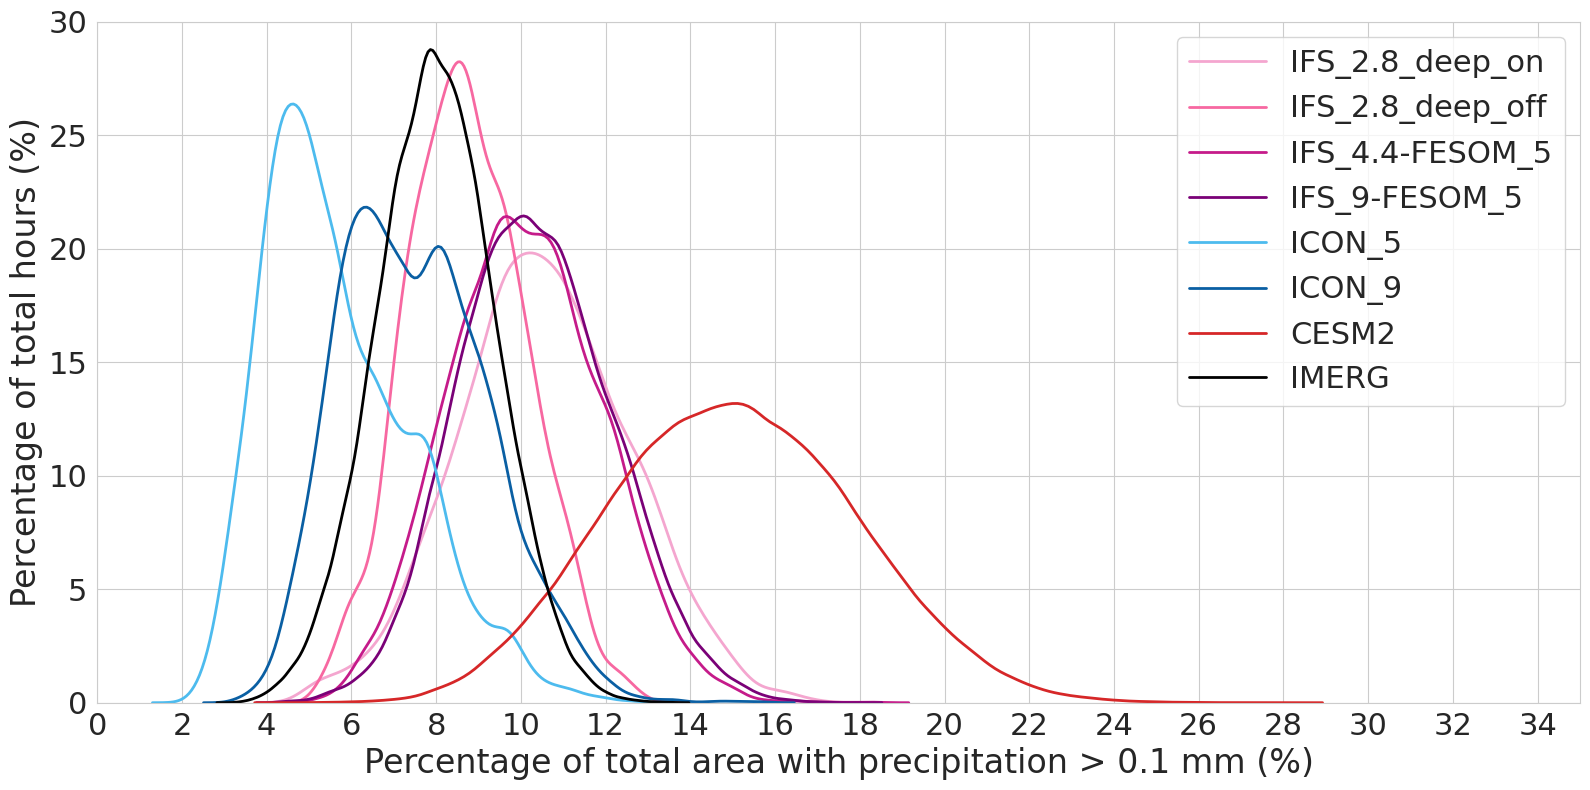

In [41]:
# 1) Common x-range + bin width
if mask == '01':
    xmin, xmax = 0, 35

elif mask == '02':
    xmin, xmax = 0, 25

elif mask == '05':
    xmin, xmax = 0, 25

elif mask == '1':
    xmin, xmax = 10, 60
bin_width  = 1.0
# 2) Your datasets
#datasets = [
#    (percent_ifs_on,    weights,     '#FF8C69', 'IFS_2.8_deep_on'),
#    (percent_ifs_off,   weights,     '#7FFF7F', 'IFS_2.8_deep_off'),
#    (percent_ifs_cycle3,weights,     '#6BB7EC', 'IFS_4.4-FESOM_5'),
#    (percent_ifs_cycle4,weights,     '#FF69B4', 'IFS_9-FESOM_5'),
#    (percent_icon_cycle3,weights,     '#C5A5CF80', 'ICON_5'),
#    (percent_cesm2,     weights_cesm2,'#FFC300','CESM2'),
#    (percent_imerg,     weights,     '#7E57C2', 'IMERG'),
#]


#datasets = [
    # IFS group – improved contrast (warm & distinct)
#    (percent_ifs_on,     weights_ifs_high,    '#D73027', 'IFS_2.8_deep_on'),   # deep red
#    (percent_ifs_off,    weights_ifs_high,    '#FC8D59', 'IFS_2.8_deep_off'),  # coral/orange
#    (percent_ifs_cycle3, weights_ifs_cycle3,  '#91BFDB', 'IFS_4.4-FESOM_5'),   # sky blue
#    (percent_ifs_cycle4, weights_ifs_cycle4,  '#4575B4', 'IFS_9-FESOM_5'),     # strong blue

    # ICON group – cohesive purples
#    (percent_icon_cycle3, weights_icon_cycle3, '#9467BD', 'ICON_5'),           # medium purple
#    (percent_icon_cycle4, weights_icon_cycle4, '#C5B0D5', 'ICON_9'),           # soft lilac

    # CESM2 – distinct highlight (gold)
#    (percent_cesm2,      weights_cesm2,       '#E6AB02', 'CESM2'),

    # IMERG – distinct but not pure black (deep violet)
#    (percent_imerg,      weights_imerg,       'k', 'IMERG'),
#]

datasets = [
    # IFS group – range of magentas (light → dark)
    (percent_ifs_on,     weights_ifs_high,    '#F4A6CF', 'IFS_2.8_deep_on'),   # pale pink-magenta
    (percent_ifs_off,    weights_ifs_high,    '#F768A1', 'IFS_2.8_deep_off'),  # mid magenta
    (percent_ifs_cycle3, weights_ifs_cycle3,  '#C51B8A', 'IFS_4.4-FESOM_5'),   # strong magenta
    (percent_ifs_cycle4, weights_ifs_cycle4,  '#7A0177', 'IFS_9-FESOM_5'),     # deep magenta
    # ICON group – range of blues (light → dark)
    (percent_icon_cycle3, weights_icon_cycle3, '#4DBBEE', 'ICON_5'),           # sky blue
    (percent_icon_cycle4, weights_icon_cycle4, '#0A5FA3', 'ICON_9'),           # deep blue
    # CMIP6 multi-model (CESM2 for other masks) – red
    (percent_gcm,        weights_gcm,         '#D62728', gcm_label),
    # IMERG – black
    (percent_imerg,      weights_imerg,       '#000000', 'IMERG'),
]

plt.figure(figsize=(16, 8))
sns.set_style("whitegrid")
plt.rc('axes', titlesize=22)
plt.rc('axes', labelsize=18)

# 3) Plot only the KDEs
for data_da, wts_da, color, label in datasets:
    # extract numpy
    x = data_da.values.ravel()
    w = wts_da.values.ravel() if hasattr(wts_da, 'values') else np.asarray(wts_da).ravel()
    # drop NaNs
    #mask_plot = ~np.isnan(x)
    #x, w = x[mask_plot], w[mask_plot]
    #print(label)
    #print(len(x))
    # normalize weights so area under curve = 1
    #w_norm = w 
  
    sns.kdeplot(
        x=x,
        weights=w,
        bw_adjust=1.0,      # tweak for smoother / sharper
        clip=(xmin, xmax),
        common_norm=False,  # each curve normalizes to its own w_norm
        fill=False,
        linewidth=2.0,
        color=color,
        label=label
    )

# 4) Rescale each line from density → percent per 0.5% bin
ax = plt.gca()
for line in ax.get_lines():
    x_vals, y_vals = line.get_data()
    y_scaled = y_vals * 100 * bin_width
    line.set_data(x_vals, y_scaled)

# 4b) CMIP6 inter-model band: range of the per-model KDE curves (Scott bandwidth of each model's
#     own sample), evaluated on the same x values as the CMIP6 multi-model line
if gcm_label == 'CMIP6':
    from scipy.stats import gaussian_kde
    gcm_line = ax.get_lines()[[lab for *_, lab in datasets].index(gcm_label)]
    x_grid = gcm_line.get_xdata()
    model_curves = np.array([gaussian_kde(d['values'])(x_grid) * 100 * bin_width for d in cmip6_models.values()])
    band_lo, band_hi = np.percentile(model_curves, CMIP6_BAND_RANGE, axis=0)
    #ax.fill_between(x_grid, band_lo, band_hi, color=gcm_line.get_color(), alpha=0.2, linewidth=0, zorder=0)
    ax.fill_between(x_grid, band_lo, band_hi, color='#888888', alpha=0.15, linewidth=0, zorder=0)

# 5) Labels, limits, legend
if mask == '01':
    xl = 'Percentage of total area with precipitation > 0.1 mm (%)'
    ax.set_ylim(0, 30)
elif mask == '02':
    xl = 'Percentage of total area with precipitation > 0.2 mm (%)'
    ax.set_ylim(0, 70)
    # Force y-ticks to be whole numbers, and reduce their number by half
    #ymin, ymax = ax.get_ylim()
    #yticks = np.arange(ymin, ymax + 1, 4)  # step=2 gives roughly half as many ticks
    #ax.set_yticks(yticks)
    #ax.set_yticklabels([f'{int(y)}' for y in yticks])  # ensures no decimals

elif mask == '05':
    xl = 'Percentage of total area with precipitation > 0.5 mm (%)'
    ax.set_ylim(0, 70)
    # Force y-ticks to be whole numbers, and reduce their number by half
    #ymin, ymax = ax.get_ylim()
    #yticks = np.arange(ymin, ymax + 1, 4)  # step=2 gives roughly half as many ticks
    #ax.set_yticks(yticks)
    #ax.set_yticklabels([f'{int(y)}' for y in yticks])  # ensures no decimals

elif mask == '1':
    xl = 'Percentage of total area with precipitation > 1 mm (%)'
    ax.set_ylim(0, 18)

plt.xlabel(xl, fontsize=24)
if mask == '1':
    plt.ylabel('Percentage of total days (%)', fontsize=24)
else:
    plt.ylabel('Percentage of total hours (%)', fontsize=24)

plt.xlim(xmin, xmax)
plt.tick_params(axis='both', which='major', labelsize=22)

xticks = np.arange(xmin, xmax, 2)
ax.set_xticks(xticks)

# build a list of Line2D handles matching your plotted lines
legend_handles = [
    Line2D([0], [0], color=color, linewidth=2.0)
    for *_, color, _ in datasets
]
# extract the labels out of your datasets tuple
legend_labels = [label for *_, _, label in datasets]
if gcm_label == 'CMIP6':
    legend_handles.append(Patch(facecolor='#888888', alpha=0.2, edgecolor='none'))
    legend_labels.append('CMIP6 model range' if tuple(CMIP6_BAND_RANGE) == (0, 100)
                         else f'CMIP6 models {CMIP6_BAND_RANGE[0]}-{CMIP6_BAND_RANGE[1]}%')

# then call legend with those handles
plt.legend(
    legend_handles,
    legend_labels,
    loc='upper right',
    prop={'size': 22},
    bbox_to_anchor=(1.0, 1.0),
    handlelength=2.5  # longer lines in legend if you like
)

plt.tight_layout()
plt.savefig('/home/jwille/images/global_paper/mid_lat_land_all_histo_precip_coverage_'+mask+'_new'
            +('_CMIP6mmm' if gcm_label == 'CMIP6' else '')+'.pdf', format='pdf',bbox_inches='tight')

plt.show()